# 01. Exploratory Data Analysis & Churn Window Justification

> **Business Objective**: Understand customer transaction patterns, order frequency, seasonality, and inter-purchase gap distributions to empirically justify the behavioral churn definition.

---


## 1. Executive Summary & Data Pipeline Verification

- **Question**: How clean is the transaction dataset after processing, and what are the core business metrics?
- **Approach**: Execute strict cleaning in `src/data.py` (dropping missing Customer IDs, separating cancellations, removing non-product codes, deduplicating) and load `data/processed/online_retail_cleaned.parquet`.
- **Result**: Filtered 1,067,371 raw transaction rows down to **776,580 clean purchase records** representing **5,852 unique customers** and **£17,068,583.72 in total gross revenue** across 24 months (Dec 2009 to Dec 2011).
- **So-What**: The dataset provides a solid 2-year temporal baseline for customer behavior tracking.


In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.theme import (
    COLOR_CORAL,
    COLOR_INK,
    COLOR_LINE,
    COLOR_NAVY,
    COLOR_TEAL,
    save_figure,
    set_matplotlib_theme,
)

set_matplotlib_theme()

# Load cleaned transactions
df = pd.read_parquet("../data/processed/online_retail_cleaned.parquet")
returns_df = pd.read_parquet("../data/processed/online_retail_returns.parquet")

print(
    f"Cleaned Purchases: {len(df):,} rows | {df['Customer ID'].nunique():,} unique customers"
)
print(f"Returns Records: {len(returns_df):,} rows")
print(f"Total Revenue: £{df['Revenue'].sum():,.2f}")
print(
    f"Date Range: {df['InvoiceDate'].min().strftime('%Y-%m-%d')} to {df['InvoiceDate'].max().strftime('%Y-%m-%d')}"
)

Cleaned Purchases: 776,580 rows | 5,852 unique customers
Returns Records: 18,744 rows
Total Revenue: £17,068,583.72
Date Range: 2009-12-01 to 2011-12-09


## 2. Transactions & Repeat Purchase Dynamics

- **Question**: What proportion of customers are repeat buyers versus one-time purchasers?
- **Approach**: Compute the number of unique order invoices per customer ID.
- **Result**: **72.35% of customers (4,234 out of 5,852)** made 2 or more purchases over the 2-year period. The median customer placed 3 orders, while the top 1% placed over 30 orders.
- **So-What**: High repeat purchase rates mean behavioral churn modeling is highly relevant for targeting retention offers.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


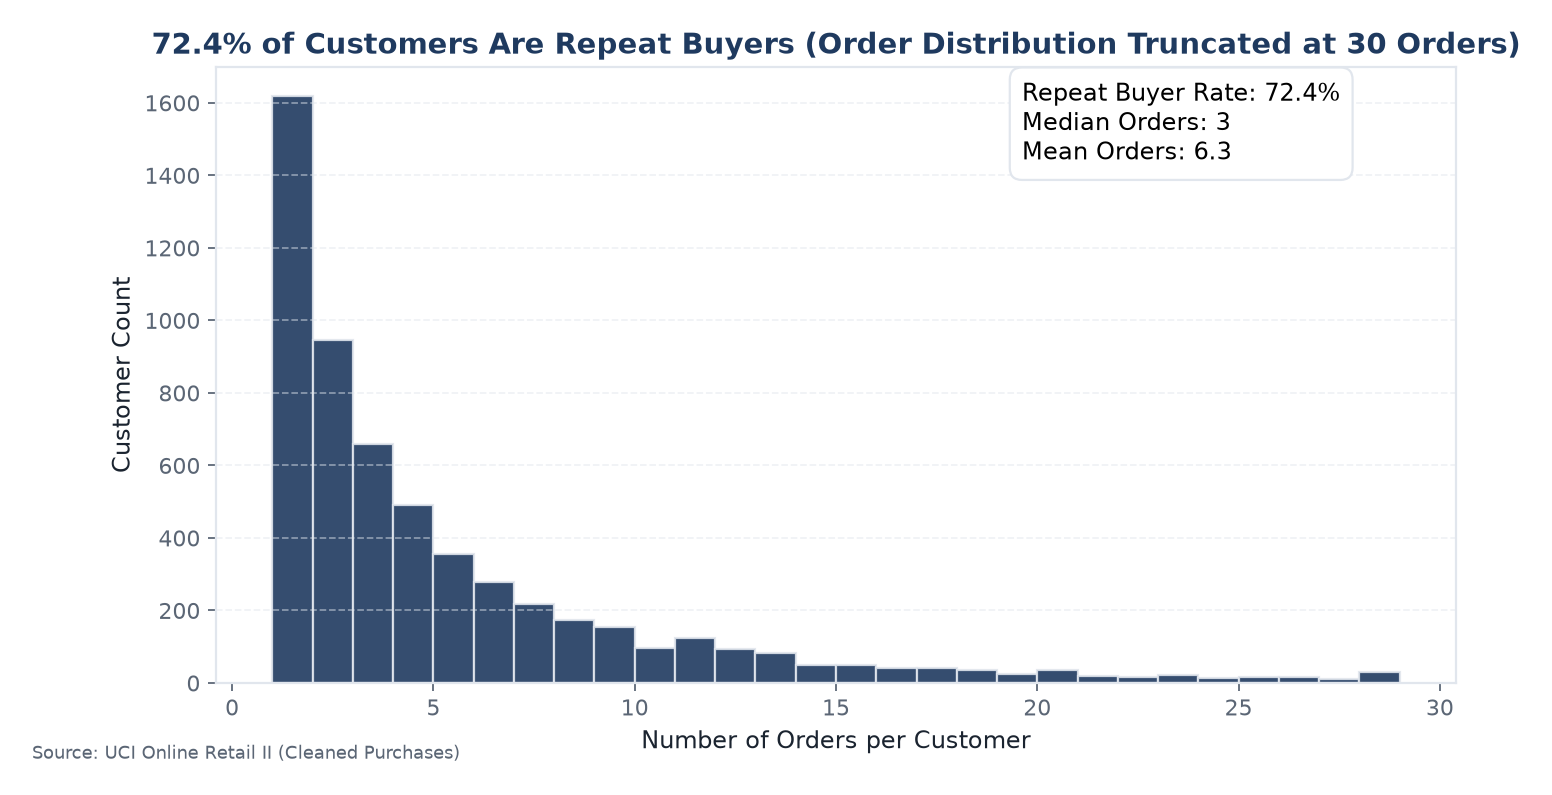

In [2]:
orders_per_cust = df.groupby("Customer ID")["Invoice"].nunique()
repeat_rate = (orders_per_cust > 1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
counts, bins, patches = ax.hist(
    orders_per_cust,
    bins=range(1, 30),
    color=COLOR_NAVY,
    edgecolor=COLOR_LINE,
    alpha=0.9,
)

ax.set_title(
    "72.4% of Customers Are Repeat Buyers (Order Distribution Truncated at 30 Orders)"
)
ax.set_xlabel("Number of Orders per Customer")
ax.set_ylabel("Customer Count")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)

# Annotate repeat rate
ax.text(
    0.65,
    0.85,
    f"Repeat Buyer Rate: {repeat_rate:.1%}\nMedian Orders: {orders_per_cust.median():.0f}\nMean Orders: {orders_per_cust.mean():.1f}",
    transform=ax.transAxes,
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": COLOR_LINE},
)

save_figure(
    fig,
    "../reports/figures/01_order_distribution.png",
    caption="Source: UCI Online Retail II (Cleaned Purchases)",
)
plt.show()

## 3. Inter-Purchase Gap Distribution (Churn Window Justification)

- **Question**: What is the empirical distribution of days between consecutive purchases, and how does it justify the $H = 90$ days churn horizon?
- **Approach**: Calculate the time gap in days between sequential orders for all repeat customers.
- **Result**: Out of **30,743 inter-purchase gaps**, the median gap is **25.0 days**, the 75th percentile is **62.0 days**, and **83.17% of all repeat orders occur within 90 days**.
- **So-What**: If a customer goes 90 consecutive days without ordering, there is an 83%+ empirical likelihood they have lapsed. This directly justifies choosing $H = 90$ days as our baseline churn cutoff.


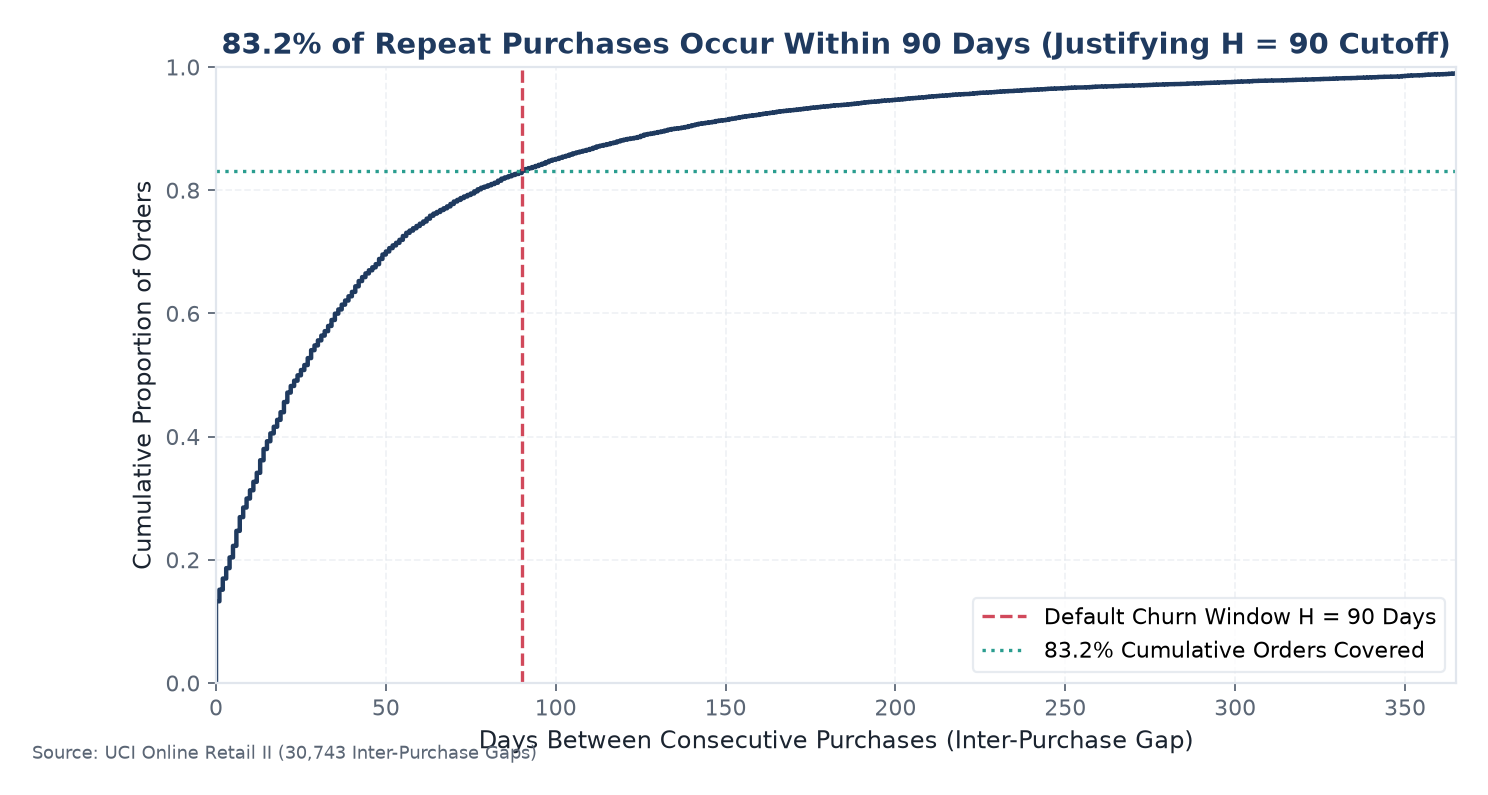

Median Inter-Purchase Gap: 25.0 days
75th Percentile Gap: 62.0 days
Proportion of Gaps <= 90 Days: 83.17%


In [3]:
cust_invoices = (
    df.groupby(["Customer ID", "Invoice"])["InvoiceDate"].min().reset_index()
)
cust_invoices = cust_invoices.sort_values(["Customer ID", "InvoiceDate"])
cust_invoices["prev_date"] = cust_invoices.groupby("Customer ID")["InvoiceDate"].shift(
    1
)
cust_invoices["gap_days"] = (
    cust_invoices["InvoiceDate"] - cust_invoices["prev_date"]
).dt.days

gaps = cust_invoices["gap_days"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))
sns.ecdfplot(gaps, ax=ax, color=COLOR_NAVY, linewidth=2)

ax.axvline(
    90,
    color=COLOR_CORAL,
    linestyle="--",
    linewidth=1.5,
    label="Default Churn Window H = 90 Days",
)
ax.axhline(
    0.8317,
    color=COLOR_TEAL,
    linestyle=":",
    linewidth=1.5,
    label="83.2% Cumulative Orders Covered",
)

ax.set_title(
    "83.2% of Repeat Purchases Occur Within 90 Days (Justifying H = 90 Cutoff)"
)
ax.set_xlabel("Days Between Consecutive Purchases (Inter-Purchase Gap)")
ax.set_ylabel("Cumulative Proportion of Orders")
ax.set_xlim(0, 365)
ax.legend(loc="lower right")
ax.grid(True, linestyle="--", alpha=0.5)

save_figure(
    fig,
    "../reports/figures/01_inter_purchase_gap_ecdf.png",
    caption="Source: UCI Online Retail II (30,743 Inter-Purchase Gaps)",
)
plt.show()

print(f"Median Inter-Purchase Gap: {gaps.median():.1f} days")
print(f"75th Percentile Gap: {gaps.quantile(0.75):.1f} days")
print(f"Proportion of Gaps <= 90 Days: {(gaps <= 90).mean():.2%}")

## 4. Sales Seasonality & Q4 Revenue Surges

- **Question**: How does transaction volume and revenue fluctuate across calendar months?
- **Approach**: Aggregate gross sales revenue by year-month.
- **Result**: Strong holiday seasonality is evident in both 2010 and 2011. Monthly revenue jumps from ~£550k in Q1–Q3 to **over £1.1M in October and November**.
- **So-What**: Features must capture seasonal indicators (e.g. Q4 purchase share) so snapshot models do not misinterpret seasonal lulls as permanent customer churn.


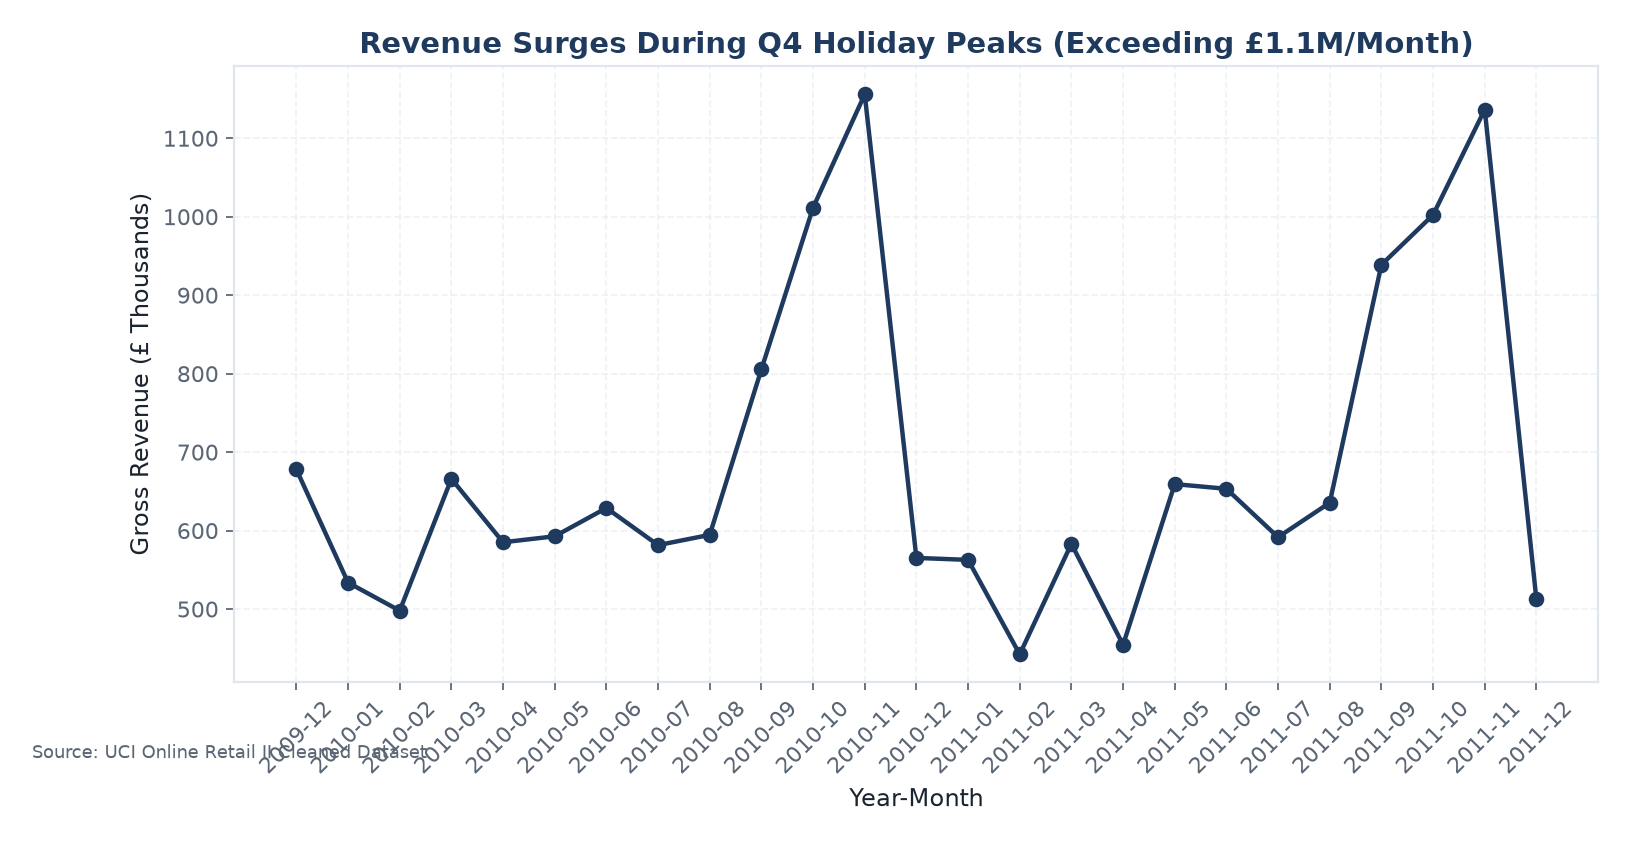

In [4]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly_rev = df.groupby("YearMonth")["Revenue"].sum() / 1e3  # in £ Thousands

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    monthly_rev.index,
    monthly_rev.values,
    marker="o",
    color=COLOR_NAVY,
    linewidth=2,
    markersize=6,
)

ax.set_title("Revenue Surges During Q4 Holiday Peaks (Exceeding £1.1M/Month)")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Gross Revenue (£ Thousands)")
plt.xticks(rotation=45)
ax.grid(True, linestyle="--", alpha=0.5)

save_figure(
    fig,
    "../reports/figures/01_monthly_seasonality.png",
    caption="Source: UCI Online Retail II Cleaned Dataset",
)
plt.show()

## 5. Geographic Mix & Market Concentration

- **Question**: What is the geographic composition of the customer base?
- **Approach**: Group total revenue by customer country.
- **Result**: The **United Kingdom accounts for 83.71% of total sales revenue (£14.29M)**, followed by Ireland (EIRE), Netherlands, Germany, and France.
- **So-What**: Country indicator features should separate UK domestic customers from international buyers.


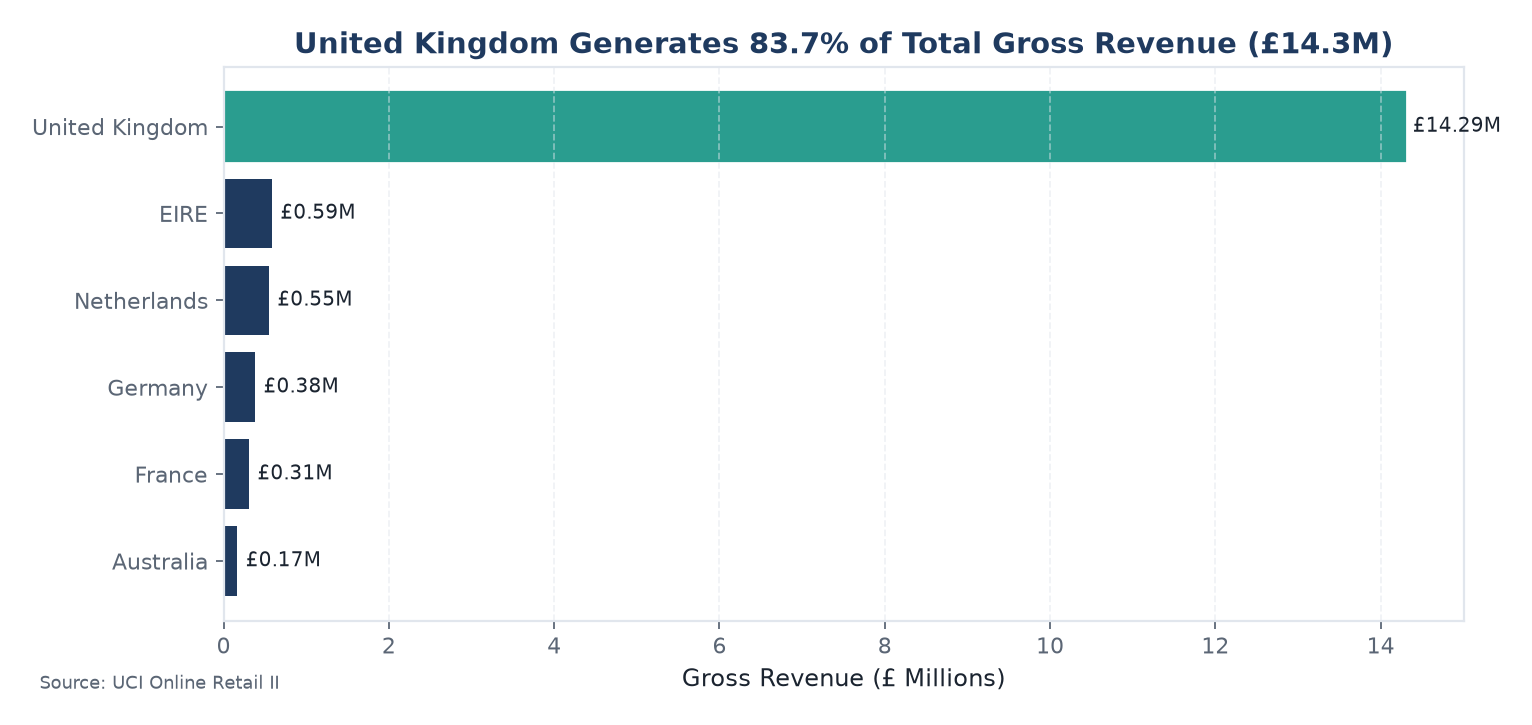

In [5]:
country_rev = (
    df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(6) / 1e6
)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(country_rev.index[::-1], country_rev.values[::-1], color=COLOR_NAVY)
bars[-1].set_color(COLOR_TEAL)  # Highlight UK

ax.set_title("United Kingdom Generates 83.7% of Total Gross Revenue (£14.3M)")
ax.set_xlabel("Gross Revenue (£ Millions)")
ax.grid(True, axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"£{width:.2f}M",
        va="center",
        fontsize=9,
        color=COLOR_INK,
    )

save_figure(
    fig,
    "../reports/figures/01_country_revenue.png",
    caption="Source: UCI Online Retail II",
)
plt.show()